Epoch 1/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6606 - loss: 0.9929 - val_accuracy: 0.7700 - val_loss: 0.6702
Epoch 2/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8100 - loss: 0.5551 - val_accuracy: 0.7950 - val_loss: 0.6343
Epoch 3/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8433 - loss: 0.4612 - val_accuracy: 0.7950 - val_loss: 0.6239
Epoch 4/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8633 - loss: 0.3984 - val_accuracy: 0.8100 - val_loss: 0.6113
Epoch 5/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8761 - loss: 0.3485 - val_accuracy: 0.8200 - val_loss: 0.5963
Epoch 6/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8922 - loss: 0.3055 - val_accuracy: 0.8200 - val_loss: 0.5981
Epoch 7/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9083 - loss: 0.2699 - val_accuracy: 0.8100 - val_loss: 0.6188
Epoch 8/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9172 - loss: 0.2408 - val_accuracy: 0.8050 - val_loss:

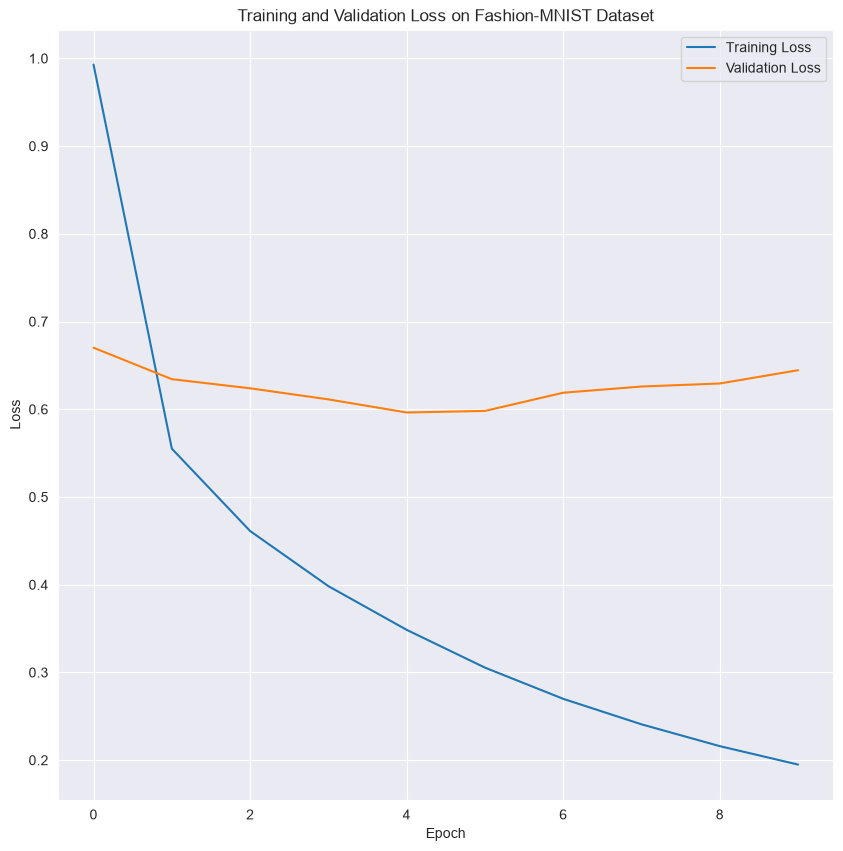

In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt

# set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# load training and test data from Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# select only the first 2000 training samples
(X_train,
 y_train) = (X_train[:2000],
             y_train[:2000])

# select only the first 400 test samples
(X_test,
 y_test) = (X_test[:400],
            y_test[:400])

# normalize pixel values from [0, 255] to [0, 1]
(X_train,
 X_test) = (X_train / 255.0,
            X_test / 255.0)

# build neural network with three hidden layers
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28)),

    tf.keras.layers.Flatten(), # convert to 1D

    # three hidden layers with 100 neurons each, using ELU and HE normal initialization
    tf.keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),
    tf.keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),
    tf.keras.layers.Dense(100, activation="elu", kernel_initializer="he_normal"),

    # output layer with one neuron for each category
    tf.keras.layers.Dense(10, activation="softmax")
])

# configure Nadam optimizer with a learning rate of 0.001
optimizer = tf.keras.optimizers.Nadam(learning_rate=0.001)

# compile model with Nadam optimizer, loss function and accuracy metric
model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ensures training is stopped if validation loss does not improve for 5 consecutive epochs,
# and restores the best weights
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# fit the model using 10% of training data as validation
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop]
)

# evaluate model on test data and report accuracy in percentage
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

plt.figure(figsize=(10, 10))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss on Fashion-MNIST Dataset")
plt.legend()
plt.grid(True)
plt.show()
